# Explicaciones para las predicciones del Reto 5

En este notebook, tendréis que importar vuestros datos y modelos para realizar un análisis usando SHAP. Tendréis que analizar los resultados obtenidos y extraer conclusiones sobre vuestros modelos. Este ejercicio os permitirá plantear cómo estos métodos pueden servir de apoyo a la supervisión humana.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

# Carga de datos y del modelo

In [ ]:
modelo = joblib.load("explic_model/modelo_prob.pkl")
print(type(modelo)) 

<class 'sklearn.linear_model._logistic.LogisticRegressionCV'>


In [ ]:
X_test = pd.read_csv("explic_model/X_test.csv")
X_train = pd.read_csv("explic_model/X_train.csv")
X_test_scaled = pd.read_csv("moexplic_modeldelo_GRUPO1/X_test_scaled.csv")
X_train_scaled = pd.read_csv("explic_model/X_train_scaled.csv")
y_test = pd.read_csv("explic_model/y_test_impago.csv")



# Explicación Local

In [9]:
# La clase 1 representa "impago"
clase_objetivo = 1
indice_clase = list(modelo.classes_).index(clase_objetivo)

# Función común para cualquier clasificador con predict_proba
def predecir_impago(datos):
    datos = pd.DataFrame(datos, columns=X_train_scaled.columns)
    return modelo.predict_proba(datos)[:, indice_clase]

# Datos de referencia para calcular las contribuciones
referencia = X_train_scaled.sample(
    n=min(100, len(X_train_scaled)),
    random_state=42
)

explainer = shap.Explainer(
    predecir_impago,
    referencia,
    algorithm="permutation",
    seed=42
)



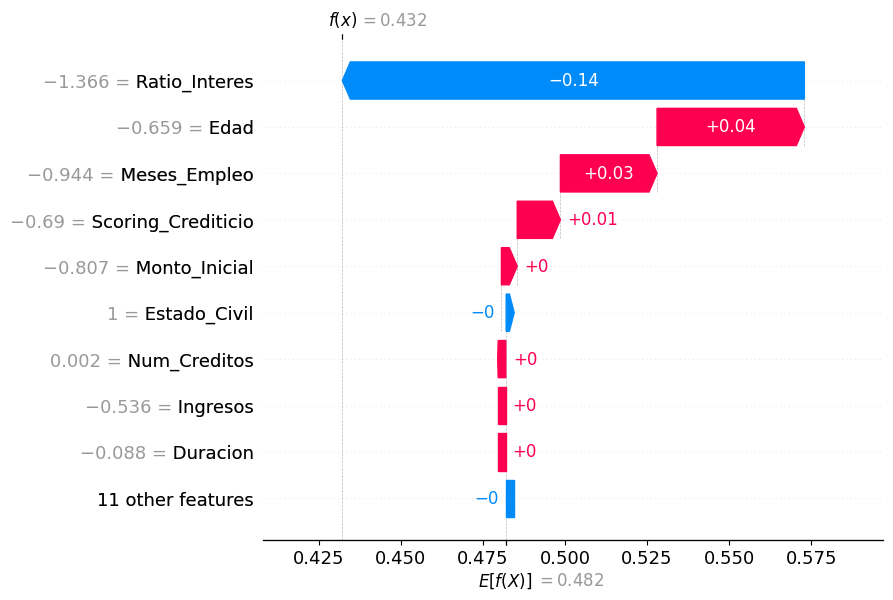

,variable,valor_scaled,valor_original,contribucion_pp
6,Ratio_Interes,-1.366161,5.49,-14.077711
0,Edad,-0.658631,33.00,4.488198
4,Meses_Empleo,-0.943921,70.00,2.944971
3,Scoring_Crediticio,-0.690026,632.00,1.315204
2,Monto_Inicial,-0.807028,7374.00,0.482003
9,Estado_Civil,1.000000,1.00,-0.145168
5,Num_Creditos,0.001524,2.00,0.014286
13,Prima,-1.061132,100.51,0.000000
18,Tipo_Jornada_Laboral_Desempleado,0.000000,0.00,0.000000
17,Tipo_Jornada_Laboral_Autónomo,1.000000,1.00,0.000000


In [10]:
indice = 0

persona = X_test_scaled.iloc[[indice]]
persona_noscaled = X_test.iloc[[indice]]
explicacion = explainer(persona)

shap.plots.waterfall(explicacion[0])

contribuciones = pd.DataFrame({
    "variable": persona.columns,
    "valor_scaled": persona.iloc[0].to_numpy(),
    "valor_original": persona_noscaled.iloc[0].to_numpy(),
    "contribucion_pp": explicacion.values[0] * 100
})

contribuciones = contribuciones.sort_values(
    "contribucion_pp",
    key=lambda columna: columna.abs(),
    ascending=False
)

display(contribuciones)

# Explicación local, respecto a subconjunto

También podemos explicar el impacto de las variables considerando un subconjunto de registros. Ej. ¿Cuáles son las variables que más contribuyen a la diferencia entre esta predicción y otras de edad similar?

**Tener en cuenta al elegir el grupo de referencia**

Si explicamos la predicción de una persona de 45 años utilizando como referencia a personas de entre 40 y 50 años, debemos recordar lo siguiente:
    
* La referencia recoge predicciones del modelo, no impagos reales. Si el valor de referencia es un 15 %, significa que el modelo estima, de media, esa probabilidad de impago para las personas del grupo.
    
* Elegir personas de una edad similar no elimina el efecto de la edad. Dentro del grupo sigue habiendo edades diferentes. Además, esas personas pueden tener ingresos, empleos y otras características distintas. Tener una edad parecida no significa tener un perfil idéntico.
    
* Comparar solo dentro de un grupo puede ocultar diferencias con otros grupos. Esta explicación ayuda a entender por qué una persona se diferencia de otras de su edad, pero no permite saber si el modelo funciona mejor o peor para otras edades.
    
* El grupo debe tener suficientes personas y elegirse con un criterio justificado. Si hay muy pocos casos, la explicación puede depender demasiado de quiénes estén incluidos. Conviene comprobar si cambia mucho al ampliar ligeramente el intervalo de edad.

**Misma predicción y distinta explicación**

Podemos explicar a la misma persona utilizando dos referencias: todos los solicitantes o solo los de una edad similar.

La predicción individual no cambia, pero las contribuciones SHAP pueden cambiar porque la comparación es diferente. No es lo mismo preguntar «¿por qué se diferencia del conjunto de solicitantes?» que «¿por qué se diferencia de personas de su edad?».

Para comparar varios modelos, utilizaremos el mismo grupo de referencia, de modo que las explicaciones respondan a una comparación común.

In [ ]:
condicion_subconjunto = X_train["Edad"].between(60,70)

In [12]:
# Datos de referencia para calcular las contribuciones
referencia = X_train_scaled.loc[X_train[condicion_subconjunto].index].sample(n=min(1000, condicion_subconjunto.sum()), random_state=42)

explainer = shap.Explainer(
    predecir_impago,
    referencia,
    algorithm="permutation",
    seed=42
)

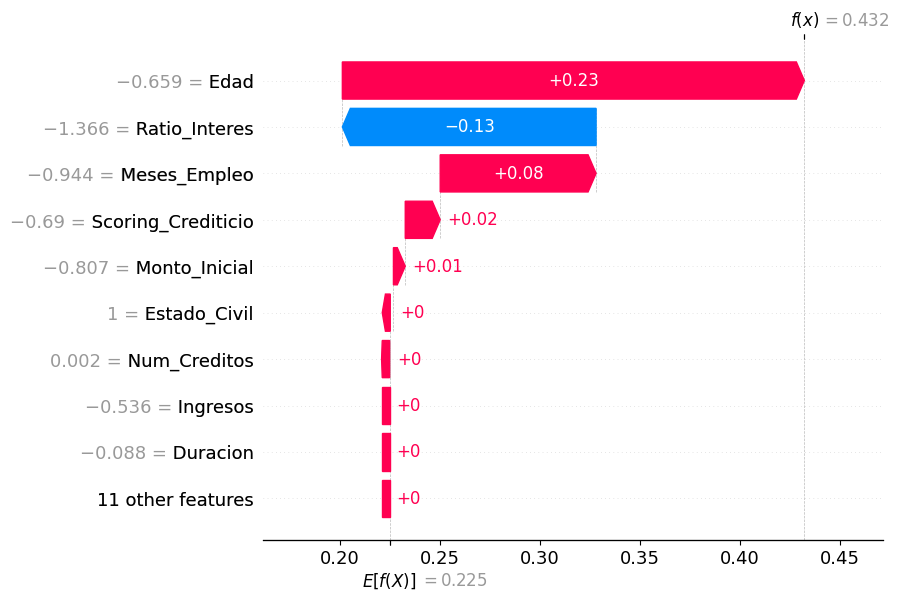

,variable,valor_scaled,valor_original,contribucion_pp
0,Edad,-0.658631,33.00,23.088177
6,Ratio_Interes,-1.366161,5.49,-12.680262
4,Meses_Empleo,-0.943921,70.00,7.789581
3,Scoring_Crediticio,-0.690026,632.00,1.746847
2,Monto_Inicial,-0.807028,7374.00,0.590668
9,Estado_Civil,1.000000,1.00,0.158933
5,Num_Creditos,0.001524,2.00,0.032858
13,Prima,-1.061132,100.51,0.000000
18,Tipo_Jornada_Laboral_Desempleado,0.000000,0.00,0.000000
17,Tipo_Jornada_Laboral_Autónomo,1.000000,1.00,0.000000


In [13]:
indice = 0

persona = X_test_scaled.iloc[[indice]]
persona_noscaled = X_test.iloc[[indice]]
explicacion = explainer(persona)

shap.plots.waterfall(explicacion[0])

contribuciones = pd.DataFrame({
    "variable": persona.columns,
    "valor_scaled": persona.iloc[0].to_numpy(),
    "valor_original": persona_noscaled.iloc[0].to_numpy(),
    "contribucion_pp": explicacion.values[0] * 100
})

contribuciones = contribuciones.sort_values(
    "contribucion_pp",
    key=lambda columna: columna.abs(),
    ascending=False
)

display(contribuciones)

# Explicación global

Las explicaciones globales agregan los resultados de las explicaciones locales de una muestra. Esto hace que podamos resumir información sobre qué efecto tiene en general cada variable sobre la predicción del modelo. Hay que tener cuidado al sacar conclusiones, ya que las correlaciones entre las variables pueden esconder efectos de estas.

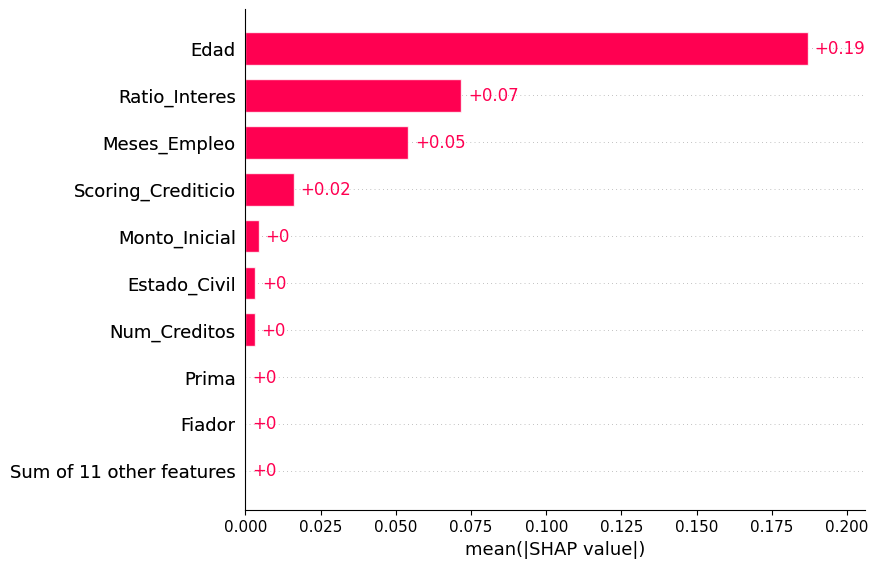

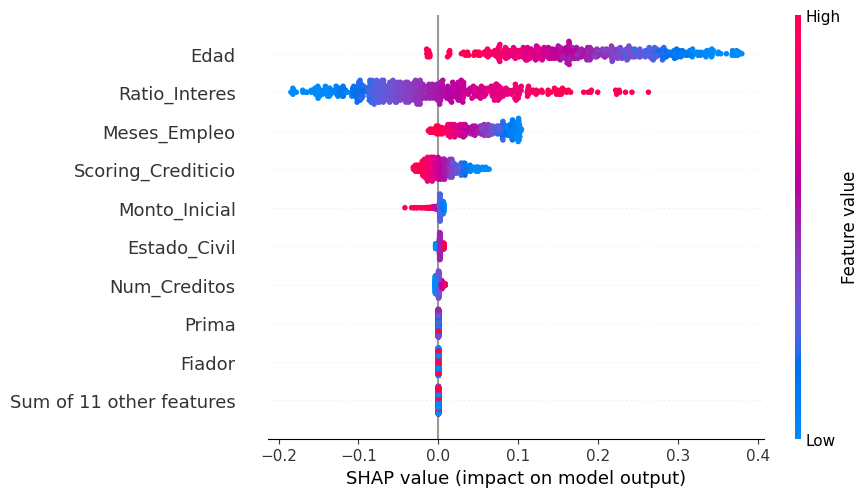

In [14]:
# Seleccionar personas para analizar el comportamiento global
X_global = X_test_scaled.sample(
    n=min(500, len(X_test_scaled)),
    random_state=42
)

valores_shap = explainer(X_global)

# Importancia global: media del valor absoluto de SHAP
shap.plots.bar(valores_shap)

# Dirección e intensidad de las contribuciones
shap.plots.beeswarm(valores_shap)